In [30]:
from pathlib import Path
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt 
import numpy as np 
import cv2
import shutil
from ultralytics import YOLO
from tensorflow import keras
import json

## Visualize Character Bounding Boxes

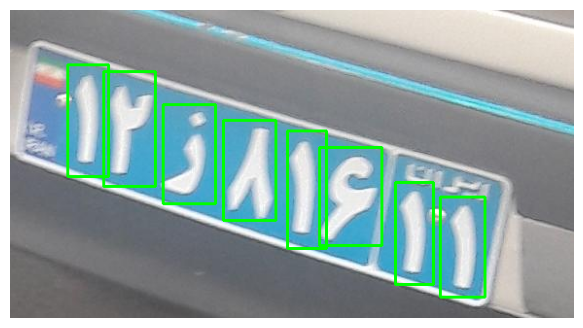

In [3]:
train_path = Path("../data/train")

xml_path = train_path / "00001.xml"
image_path = xml_path.with_suffix(".jpg")

tree = ET.parse(xml_path)
root = tree.getroot()

image = cv2.imread(str(image_path))

for obj in root.findall("object"):

    box = obj.find("bndbox")

    xmin = int(box.find("xmin").text)
    ymin = int(box.find("ymin").text)
    xmax = int(box.find("xmax").text)
    ymax = int(box.find("ymax").text)

    cv2.rectangle(
        image,
        (xmin, ymin),
        (xmax, ymax),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12, 4))
plt.imshow(
    cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
)
plt.axis("off")
plt.show()

## Convert XML Bounding Boxes to YOLO Format

In [4]:
def convert_xml_to_yolo(xml_path, image_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    image = cv2.imread(str(image_path))
    image_height, image_width = image.shape[:2]

    yolo_annotations = []

    for obj in root.findall("object"):
        box = obj.find("bndbox")

        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)

        x_center = ((xmin + xmax) / 2) / image_width
        y_center = ((ymin + ymax) / 2) / image_height

        width = (xmax - xmin) / image_width
        height = (ymax - ymin) / image_height

        yolo_annotations.append(
            [0, x_center, y_center, width, height]
        )

    return yolo_annotations

## Test YOLO Annotation Conversion

In [5]:
xml_path = train_path / "00001.xml"
image_path = xml_path.with_suffix(".jpg")

annotations = convert_xml_to_yolo(
    xml_path,
    image_path
)

for annotation in annotations:
    print(annotation)

[0, 0.13793103448275862, 0.3580441640378549, 0.07241379310344828, 0.3627760252365931]
[0, 0.21120689655172414, 0.38485804416403785, 0.09137931034482759, 0.3722397476340694]
[0, 0.31724137931034485, 0.4668769716088328, 0.09310344827586207, 0.3217665615141956]
[0, 0.4241379310344828, 0.5189274447949527, 0.09310344827586207, 0.3249211356466877]
[0, 0.5258620689655172, 0.582018927444795, 0.06896551724137931, 0.38170347003154576]
[0, 0.603448275862069, 0.6041009463722398, 0.1103448275862069, 0.3186119873817035]
[0, 0.7163793103448276, 0.7239747634069401, 0.06724137931034482, 0.3312302839116719]
[0, 0.8017241379310345, 0.7681388012618297, 0.07931034482758621, 0.3249211356466877]


## Prepare YOLO Dataset Split

In [6]:
def prepare_yolo_split(source_dir, output_dir, split_name):
    source_dir = Path(source_dir)
    output_dir = Path(output_dir)

    images_dir = output_dir / "images" / split_name
    labels_dir = output_dir / "labels" / split_name

    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    xml_files = sorted(source_dir.glob("*.xml"))

    for xml_path in xml_files:
        image_path = xml_path.with_suffix(".jpg")

        annotations = convert_xml_to_yolo(
            xml_path,
            image_path
        )

        shutil.copy(
            image_path,
            images_dir / image_path.name
        )

        label_path = labels_dir / f"{xml_path.stem}.txt"

        with open(label_path, "w") as f:
            for annotation in annotations:
                class_id, x_center, y_center, width, height = annotation

                f.write(
                    f"{class_id} "
                    f"{x_center} "
                    f"{y_center} "
                    f"{width} "
                    f"{height}\n"
                )

## Build YOLO Dataset

In [8]:
yolo_output = "../data/yolo_dataset"

prepare_yolo_split(
    "../data/train",
    yolo_output,
    "train"
)

prepare_yolo_split(
    "../data/validation",
    yolo_output,
    "validation"
)

prepare_yolo_split(
    "../data/test",
    yolo_output,
    "test"
)

## Load Pretrained YOLO Model

In [10]:
detector = YOLO("yolo11n.pt")

In [11]:
yaml_path = Path("../data/yolo_dataset/data.yaml")

print(yaml_path.resolve())
print(yaml_path.exists())

/Users/parsa.h/Python/Deep Learning/iranian-license-plate-ocr/data/yolo_dataset/data.yaml
False


## Train Character Detector

In [13]:
results = detector.train(
    data="../data/yolo_dataset/data.yaml",
    epochs=3,
    imgsz=640,
    batch=16,
    device="mps"
)

Ultralytics 8.4.170 🚀 Python-3.9.6 torch-2.8.0 MPS (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../data/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-12, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap

In [25]:
import torch

print(torch.backends.mps.is_available())
print(torch.backends.mps.is_built())

True
True


In [14]:
detector = YOLO(
    "runs/detect/train-12/weights/best.pt"
)

In [15]:
results = detector.predict(
    source="../data/sample_plate.jpg",
    conf=0.5
)


image 1/1 /Users/parsa.h/Python/Deep Learning/iranian-license-plate-ocr/src/../data/sample_plate.jpg: 384x640 8 characters, 34.2ms
Speed: 3.6ms preprocess, 34.2ms inference, 4.8ms postprocess per image at shape (1, 3, 384, 640)


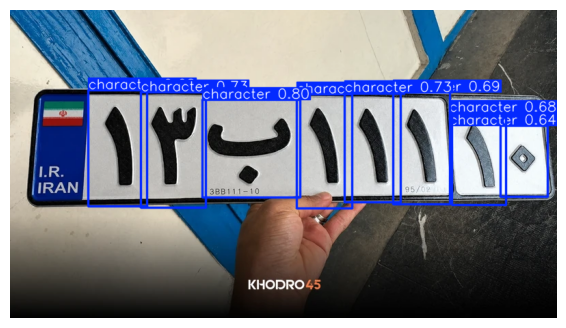

In [16]:
result = results[0]

annotated_image = result.plot()

plt.figure(figsize=(12, 4))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Get Bounding Boxes from YOLO Predictions

In [17]:
boxes = result.boxes.xyxy.cpu().numpy()

## Load Original Plate Image

In [18]:
plate_image = cv2.imread("../data/sample_plate.jpg")

## Sort Bounding Boxes from Left to Right

In [23]:
boxes = sorted(boxes, key=lambda box: box[0])

## Crop Detected Characters

In [24]:
cropped_characters = []

for box in boxes:
    xmin, ymin, xmax, ymax = map(int, box)

    character = plate_image[ymin:ymax, xmin:xmax]

    cropped_characters.append(character)

## Visualize Cropped Characters

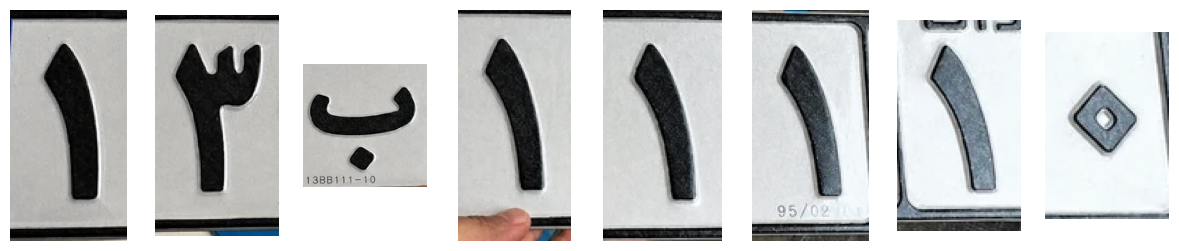

In [25]:
plt.figure(figsize=(15, 3))

for i, character in enumerate(cropped_characters):
    plt.subplot(1, len(cropped_characters), i + 1)

    plt.imshow(cv2.cvtColor(character, cv2.COLOR_BGR2RGB))
    plt.axis("off")

plt.show()

## Preprocess Cropped Characters for CNN

In [26]:
processed_characters = []

for character in cropped_characters:
    resized_character = cv2.resize(character, (32, 64))

    gray_character = cv2.cvtColor(
        resized_character,
        cv2.COLOR_BGR2GRAY
    )

    normalized_character = (
        gray_character.astype("float32") / 255.0
    )

    normalized_character = np.expand_dims(
        normalized_character,
        axis=-1
    )

    processed_characters.append(normalized_character)

In [27]:
X_characters = np.array(processed_characters)

print(X_characters.shape)

(8, 64, 32, 1)


In [29]:
cnn_model = keras.models.load_model(
    "../models/license_plate_character_cnn.keras"
)

## Load Character Class Mapping

In [31]:
with open("../models/class_mapping.json", "r", encoding="utf-8") as f:
    index_to_class = json.load(f)

index_to_class = {
    int(index): label
    for index, label in index_to_class.items()
}

## Predict Cropped Characters

In [35]:
predictions = cnn_model.predict(X_characters)

predicted_indices = np.argmax(predictions, axis=1)

predicted_labels = [
    index_to_class[index]
    for index in predicted_indices
]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


In [36]:
print(predicted_labels)

['1', '3', 'ب', '1', '1', '1', '1', '0']


## Build Plate Text

In [44]:
plate_text = "\u200e".join(predicted_labels)
print("Predicted Plate:", plate_text)

Predicted Plate: 1‎3‎ب‎1‎1‎1‎1‎0


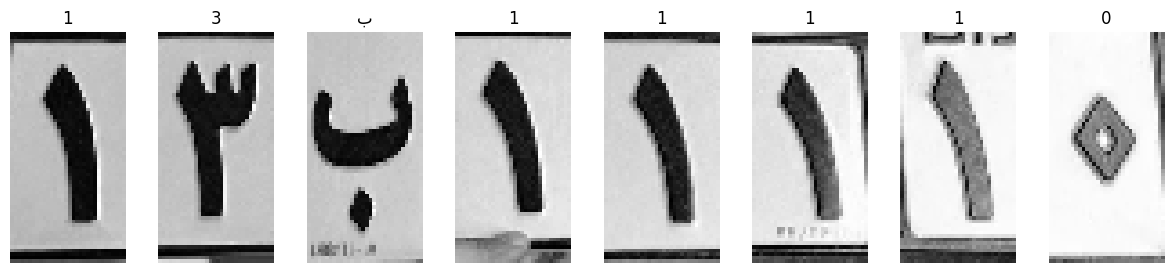

In [38]:
plt.figure(figsize=(15, 3))

for i, character in enumerate(X_characters):
    plt.subplot(1, len(X_characters), i + 1)

    plt.imshow(character.squeeze(), cmap="gray")
    plt.title(predicted_labels[i])
    plt.axis("off")

plt.show()

## Build Complete License Plate Recognition Pipeline

In [45]:
def predict_plate(image_path):
    plate_image = cv2.imread(image_path)

    results = detector.predict(
        source=image_path,
        conf=0.5
    )

    result = results[0]

    boxes = result.boxes.xyxy.cpu().numpy()

    boxes = sorted(
        boxes,
        key=lambda box: box[0]
    )

    cropped_characters = []

    for box in boxes:
        xmin, ymin, xmax, ymax = map(int, box)

        character = plate_image[
            ymin:ymax,
            xmin:xmax
        ]

        cropped_characters.append(character)

    processed_characters = []

    for character in cropped_characters:
        resized_character = cv2.resize(
            character,
            (32, 64)
        )

        gray_character = cv2.cvtColor(
            resized_character,
            cv2.COLOR_BGR2GRAY
        )

        normalized_character = (
            gray_character.astype("float32") / 255.0
        )

        normalized_character = np.expand_dims(
            normalized_character,
            axis=-1
        )

        processed_characters.append(
            normalized_character
        )

    X_characters = np.array(
        processed_characters
    )

    predictions = cnn_model.predict(
        X_characters,
        verbose=0
    )

    predicted_indices = np.argmax(
        predictions,
        axis=1
    )

    predicted_labels = [
        index_to_class[index]
        for index in predicted_indices
    ]

    plate_text = "\u200e".join(
        predicted_labels
    )

    return plate_text

In [46]:
predicted_plate = predict_plate(
    "../data/sample_plate.jpg"
)

print(predicted_plate)


image 1/1 /Users/parsa.h/Python/Deep Learning/iranian-license-plate-ocr/src/../data/sample_plate.jpg: 384x640 8 characters, 47.2ms
Speed: 19.6ms preprocess, 47.2ms inference, 10.6ms postprocess per image at shape (1, 3, 384, 640)
1‎3‎ب‎1‎1‎1‎1‎0
